# Module 5 Lab 2: Textbook Problem 5.3

### Housing Type Bar Chart

**Name:** Mac Mckay

**Course:** CS 82A

**Repo:** https://github.com/raulmckay-blip/cs82a-portfolio

## Overview

This project takes the raw customer data, removes the rows with a missing housing type, and charts how many customers fall into each housing type.

## Load the data

The file is tab-separated, so I added `sep='\t'`. Without it pandas looks for commas and puts everything in one column.

In [2]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_theme(style='whitegrid')

cust = pd.read_csv('custdata.tsv', sep='\t')
print(cust.shape)   # 1,000 customers, 11 columns
cust.head()

(1000, 11)


,custid,sex,is.employed,income,marital.stat,health.ins,housing.type,recent.move,num.vehicles,age,state.of.res
0,2068,F,NaN,11300,Married,True,Homeowner free and clear,False,2.0,49.0,Michigan
1,2073,F,NaN,0,Married,True,Rented,True,3.0,40.0,Florida
2,2848,M,True,4500,Never Married,False,Rented,True,3.0,22.0,Georgia
3,5641,M,True,20000,Never Married,False,Occupied with no rent,False,0.0,22.0,New Mexico
4,6369,F,True,12000,Never Married,True,Rented,True,1.0,31.0,Florida


## Zoomin in: The housing types 

In [3]:
cust['housing.type'].value_counts(dropna=False)

housing.type
Homeowner with mortgage/loan    412
Rented                          364
Homeowner free and clear        157
NaN                              56
Occupied with no rent            11
Name: count, dtype: int64

Before removing anything, I counted every housing type including the missing ones. There are four real types plus 56 missing. The file writes them as `NA`, and pandas reads that as missing on its own, so I didn't have to convert anything.

## Remove the NA rows (and count them)

The book's hint says to subset with a condition on the housing-type field, so I filtered for rows where `housing.type` is not missing (`.notna()`). I filtered on just that column on purpose. When I checked, running `dropna()` on the whole table would also drop rows missing other columns (like `is.employed`, with 328 missing) and leave only 664 customers.

In [4]:
print('Missing per column:')
print(cust.isna().sum())
print()
print('Rows left if I dropped NA in ANY column:', len(cust.dropna()))

Missing per column:
custid            0
sex               0
is.employed     328
income            0
marital.stat      0
health.ins        0
housing.type     56
recent.move      56
num.vehicles     56
age               0
state.of.res      0
dtype: int64

Rows left if I dropped NA in ANY column: 664


In [5]:
before = len(cust)
housing = cust[cust['housing.type'].notna()]   # keep only rows that have a housing type
after = len(housing)
dropped = before - after

print(f'Before: {before} rows')
print(f'After:  {after} rows')
print(f'Dropped {dropped} rows ({dropped / before:.1%}) with no housing type')

Before: 1000 rows
After:  944 rows
Dropped 56 rows (5.6%) with no housing type


In [6]:
# make sure nothing missing is left
print('NA left:', housing['housing.type'].isna().sum())

counts = housing['housing.type'].value_counts()   
counts

NA left: 0


housing.type
Homeowner with mortgage/loan    412
Rented                          364
Homeowner free and clear        157
Occupied with no rent            11
Name: count, dtype: int64

## Sorted bar chart

I made the bars horizontal because the housing type names are long and overlapped on the x-axis. 

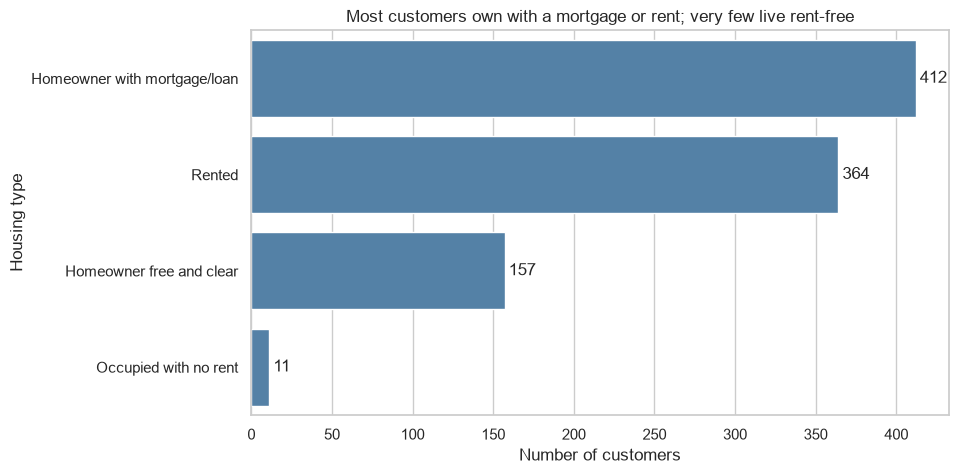

In [7]:
plt.figure(figsize=(9, 5))
ax = sns.countplot(data=housing, y='housing.type', order=counts.index, color='steelblue')
ax.bar_label(ax.containers[0], padding=3)   # show the count on each bar
plt.title('Most customers own with a mortgage or rent; very few live rent-free')
plt.xlabel('Number of customers')
plt.ylabel('Housing type')
plt.show()

Homeowners with a mortgage or loan are the biggest group (412), with renters close behind (364), then people who own their home outright (157). Only 11 customers live somewhere without paying rent.

## Rows excluded

**I excluded 56 of the 1,000 rows (5.6%) because their housing type was NA, so the chart is based on 944 customers.**

## AI Use

I used AI to help with syntax and refine wording on this lab.